# Türkçe Yemek Tarifleri Üzerinde Doğal Dil İşleme Projesi

Bu projede 3.320 adet Türkçe yemek tarifinden oluşan veri seti kullanılarak derste işlenen Doğal Dil İşleme yöntemleri uygulanmıştır:
1. **Veri Keşfi ve Dengesiz Veri Analizi**
2. **Metin Ön İşleme** (Tokenization, Stop Words Temizliği, Lemmatization)
3. **TF-IDF ve Kosinüs Benzerliği ile Benzer Tarif Öneri Sistemi**
4. **Denetimli Öğrenme ile Kategori Sınıflandırması** (CountVectorizer, TF-IDF, Multinomial Naive Bayes ve Karar Ağacı)

In [1]:
import numpy as np 
import pandas as pd 
import string
import ast
import re
import matplotlib.pyplot as plt
from simplemma import text_lemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier

## 1. Metin Ön İşleme Hazırlığı (Stop Words ve Lemmatization)
Metinlerde sık geçen ancak model için ayırt edici olmayan dolgu sözcükleri (`stopwords.txt`) yüklenmektedir. Yemek tariflerinde kritik malzeme isimleri olan **"et"** ve **"un"** kelimeleri dolgu sözcükleri kümesinden çıkarılmıştır. 

Ayrıca Türkçe kök bulma (lemmatization) aşamasında `simplemma` kütüphanesinin `-ma/-me` yapım ekini olumsuzluk eki gibi kesmesini önlemek amacıyla *kıyma, sarma, dolma* gibi yemek isimleri korunacak kelimeler kümesine eklenmiştir.

In [2]:
stop_words = None
with open("stopwords.txt", "r" , encoding="utf-8") as stop_file:
    stop_words = set(stop_file.read().splitlines())

stop_words.discard("et")
stop_words.discard("un")

In [3]:
korunacak_kelimeler = {
    "kıyma", "sarma", "dolma", "kavurma", "haşlama",
    "kızartma", "dondurma", "kızarma", "közleme"
}

def clean_text(text):
    text = text.replace("Â", "a")
    text = text.replace("â", "a")
    text = text.replace("î", "i")
    text = text.replace("Î", "i")
    text = text.replace("İ", "i")
    text = text.replace("I", "ı")
    text = text.replace(u"\u00A0", " ")
    text = text.replace("|", " ")

    text = re.sub(r"\n", " ", text)
    text = re.sub(r"[^A-Za-zâîığüşöçİĞÜŞÖÇ]+", " ", text)

    kelimeler = text.lower().strip().split()
    temiz_kelimeler = []

    for word in kelimeler:
        if word in korunacak_kelimeler:
            temiz_kelimeler.append(word)
        else:
            kokler = text_lemmatizer(word, lang="tr")
            for k in kokler:
                if k not in stop_words:
                    temiz_kelimeler.append(k)

    return " ".join(temiz_kelimeler)


## 2. Veri Setinin Yüklenmesi, CSV Formatına Dönüştürülmesi ve İncelenmesi
Orijinal olarak `.json` formatında elde edilen veri seti (`tarifler.json`), ders içi çalışmalarla uyumlu olması adına `pandas` kullanılarak `.csv` formatına (`tarifler.csv`) dönüştürülmüştür. Ardından veri setinin boyutu, sütun yapısı, eksik değer kontrolü ve kategorilere göre dağılımı incelenmiştir. Grafikte görüldüğü üzere kategoriler arasında belirgin bir **dengesiz veri dağılımı (class imbalance)** bulunmaktadır (`ana yemek`: 1256, `tatlı`: 832, `çorba`: 293, `turşu`: 17).

In [4]:
try:
    df = pd.read_json("tarifler.json")
except ValueError:
    df = pd.read_json("tarifler.json", lines=True)

In [5]:
df.to_csv("tarifler.csv", index=False, encoding="utf-8-sig")

In [6]:
df = pd.read_csv("tarifler.csv")
print("Boyut:", df.shape)
print("Sütunlar:", df.columns.tolist())
df.head(2)

Boyut: (3320, 10)
Sütunlar: ['tarif_adi', 'kategori', 'porsiyon', 'hazirlik_suresi_dk', 'pisirme_suresi_dk', 'zorluk', 'pisirme_yontemi', 'malzemeler', 'yapilis_adimlari', '_source']


,tarif_adi,kategori,porsiyon,hazirlik_suresi_dk,pisirme_suresi_dk,zorluk,pisirme_yontemi,malzemeler,yapilis_adimlari,_source
0,Sodalı Köfte,ana yemek,NaN,NaN,20.0,kolay,['fırın'],"[{'isim': 'kıyma', 'miktar': 500, 'birim': 'gr...",['Derin bir kap içine 1 adet büyük boy soğan r...,"{'raw_name': 'Sodalı Köfte', 'index': 0, 'cont..."
1,Piliç Topkapı,ana yemek,NaN,180.0,55.0,orta,['fırın'],"[{'isim': 'tavuk but', 'miktar': 4, 'birim': '...",['Tavuk butlarını kasabınızdan rica ederek kem...,"{'raw_name': 'Piliç Topkapı', 'index': 1, 'con..."


In [7]:
gerekli_sutunlar = ['tarif_adi', 'kategori', 'malzemeler', 'yapilis_adimlari']
print("Eksik değer sayıları:\n", df[gerekli_sutunlar].isnull().sum())

Eksik değer sayıları:
 tarif_adi           0
kategori            0
malzemeler          0
yapilis_adimlari    0
dtype: int64


In [8]:
kategori_sayilari = df['kategori'].value_counts()
print("\nKategori Dağılımı:\n", kategori_sayilari)


Kategori Dağılımı:
 kategori
ana yemek       1256
tatlı            832
salata           337
çorba            293
kahvaltı         285
atıştırmalık     264
içecek            36
turşu             17
Name: count, dtype: int64


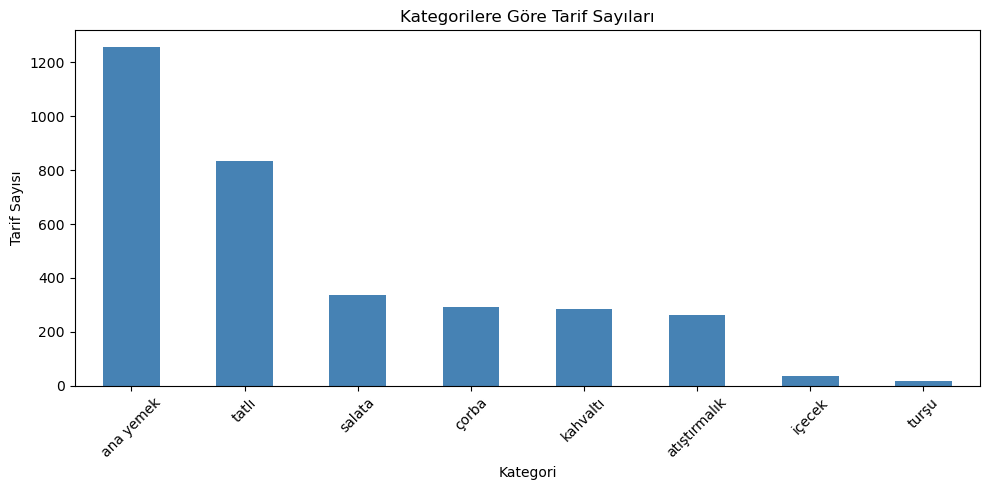

In [9]:
plt.figure(figsize=(10, 5))
kategori_sayilari.plot(kind='bar', color='steelblue')
plt.title("Kategorilere Göre Tarif Sayıları")
plt.xlabel("Kategori")
plt.ylabel("Tarif Sayısı")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Malzeme ve Yapılış Metinlerinin Ayrıştırılıp Temizlenmesi
CSV dosyasında metin (string) formatında saklanan liste ve sözlük yapıları `ast.literal_eval` ile Python listelerine dönüştürülmekte, yalnızca malzeme isimleri ve yapılış adımları birleştirilerek `clean_text` fonksiyonundan geçirilmektedir. Kategoriyi doğrudan ele vereceği için `tarif_adi` sütunu temizlenen metne dahil edilmemiştir.

In [10]:
df["malzeme_list"] = df["malzemeler"].apply(ast.literal_eval)
df["yapilis_list"] = df["yapilis_adimlari"].apply(ast.literal_eval)
df.head(2)

,tarif_adi,kategori,porsiyon,hazirlik_suresi_dk,pisirme_suresi_dk,zorluk,pisirme_yontemi,malzemeler,yapilis_adimlari,_source,malzeme_list,yapilis_list
0,Sodalı Köfte,ana yemek,NaN,NaN,20.0,kolay,['fırın'],"[{'isim': 'kıyma', 'miktar': 500, 'birim': 'gr...",['Derin bir kap içine 1 adet büyük boy soğan r...,"{'raw_name': 'Sodalı Köfte', 'index': 0, 'cont...","[{'isim': 'kıyma', 'miktar': 500, 'birim': 'gr...",[Derin bir kap içine 1 adet büyük boy soğan re...
1,Piliç Topkapı,ana yemek,NaN,180.0,55.0,orta,['fırın'],"[{'isim': 'tavuk but', 'miktar': 4, 'birim': '...",['Tavuk butlarını kasabınızdan rica ederek kem...,"{'raw_name': 'Piliç Topkapı', 'index': 1, 'con...","[{'isim': 'tavuk but', 'miktar': 4, 'birim': '...",[Tavuk butlarını kasabınızdan rica ederek kemi...


In [11]:
def clean_row(row):
    malzemeler = [str(m["isim"]) for m in row["malzeme_list"] if m["isim"]]
    malzeme_str = clean_text(" ".join(malzemeler))
    yapilis_str = clean_text(" ".join(row["yapilis_list"]))
    return malzeme_str + " " + yapilis_str

clean_row(df.iloc[0])

'kıyma soğan galeta un tuz kırmızı toz biber kırmızı pul biber kimyon karabiber kabartma toz soda derin kap iç adet büyük boy soğan rendele rendele soğan su su süz ardından üzer yarım kilo kıyma koyun kaba yarım çay bardak galeta un tatlı kaşık tuz çay kaşık dolu kırmızı toz biber çay kaşık kırmızı pul biber çay kaşık kimyon yarım çay kaşık karabiber yarım paket kabartma toz koyun son köfte harç üzer çay bardak soda dök köfte harç el iyi yoğur hazırla soda köfte harç buzdolab saat dinlen bırak dinlen köfte harç ceviz büyük parça al el yuvarlak oval şekil ver şekil ver köfte yağlı kağıt seri fırın tepsi iç dizin köfte yan istek domates biber koy soda köfte önceden ısıt derece fırın ver üzer güzel kızar pişir'

In [12]:
df["clean"] = df.apply(lambda row: clean_row(row), axis=1)
df.head(2)

,tarif_adi,kategori,porsiyon,hazirlik_suresi_dk,pisirme_suresi_dk,zorluk,pisirme_yontemi,malzemeler,yapilis_adimlari,_source,malzeme_list,yapilis_list,clean
0,Sodalı Köfte,ana yemek,NaN,NaN,20.0,kolay,['fırın'],"[{'isim': 'kıyma', 'miktar': 500, 'birim': 'gr...",['Derin bir kap içine 1 adet büyük boy soğan r...,"{'raw_name': 'Sodalı Köfte', 'index': 0, 'cont...","[{'isim': 'kıyma', 'miktar': 500, 'birim': 'gr...",[Derin bir kap içine 1 adet büyük boy soğan re...,kıyma soğan galeta un tuz kırmızı toz biber kı...
1,Piliç Topkapı,ana yemek,NaN,180.0,55.0,orta,['fırın'],"[{'isim': 'tavuk but', 'miktar': 4, 'birim': '...",['Tavuk butlarını kasabınızdan rica ederek kem...,"{'raw_name': 'Piliç Topkapı', 'index': 1, 'con...","[{'isim': 'tavuk but', 'miktar': 4, 'birim': '...",[Tavuk butlarını kasabınızdan rica ederek kemi...,tavuk but süt karabiber kırmızı toz biber tuz ...


## 4. TF-IDF Matrisinin Oluşturulması ve Benzer Tarif Öneri Sistemi
Temizlenmiş tarif metinleri üzerinden sözlük (`word2idx`) oluşturulup `numpy` kullanılarak **TF (Term Frequency)**, **IDF (Inverse Document Frequency)** ve **TF-IDF** matrisleri sıfırdan hesaplanmaktadır. Böylece tariflerin çoğunda geçen ortak kelimelerin ağırlığı azaltılırken ayırt edici malzemelerin ağırlığı artırılır.

In [13]:
tarifler = df["clean"].values

word2idx = {}
i = 0

for tarif in tarifler:
    for sozcuk in tarif.split():
        if sozcuk not in word2idx:
            word2idx[sozcuk] = i
            i += 1

tarif_sayisi = len(tarifler)
sozluk_buyuklugu = len(word2idx)

print("Tarif sayısı:", tarif_sayisi)
print("Sözlük büyüklüğü:", sozluk_buyuklugu)

Tarif sayısı: 3320
Sözlük büyüklüğü: 2350


In [14]:
tf = np.zeros((tarif_sayisi, sozluk_buyuklugu))

for i, tarif in enumerate(tarifler):
    sozcukler = tarif.split()
    for sozcuk in sozcukler:
        tf[i, word2idx[sozcuk]] += 1
    
    if len(sozcukler) > 0:
        tf[i] = tf[i] / len(sozcukler)

print(tf[0])

[0.01574803 0.02362205 0.01574803 ... 0.         0.         0.        ]


In [15]:
doc_freq = np.sum(tf > 0, axis=0)
idf = np.log(tarif_sayisi / doc_freq)

tf_idf = tf * idf
print("TF-IDF matris boyutu:", tf_idf.shape)

TF-IDF matris boyutu: (3320, 2350)


### Kosinüs Benzerliği (Cosine Similarity) ile Benzer Tarif Sorgulama
Doküman uzunluklarından etkilenmeden iki tarif vektörü arasındaki açıyı ölçmek için Kosinüs Benzerliği ($\cos \theta = \frac{v_1 \cdot v_2}{\|v_1\| \|v_2\|}$) kullanılmaktadır.

In [16]:
def cos_sim(v1, v2):
    payda = np.linalg.norm(v1) * np.linalg.norm(v2)
    if payda == 0:
        return 0.0
    return np.dot(v1, v2) / payda

def tarif2str(row_index):
    tarif = df.iloc[row_index]
    adi = tarif["tarif_adi"]
    kategori = tarif["kategori"]
    malzemeler = ", ".join([str(m["isim"]) for m in tarif["malzeme_list"] if m["isim"]])
    if len(malzemeler) > 200:
        malzemeler = malzemeler[:200] + "..."
    
    return f"Tarif adı: {adi}\nKategori: {kategori}\nMalzemeler: {malzemeler}"

print(tarif2str(0))

Tarif adı: Sodalı Köfte
Kategori: ana yemek
Malzemeler: kıyma, soğan, galeta unu, tuz, kırmızı toz biber, kırmızı pul biber, kimyon, karabiber, kabartma tozu, soda


In [17]:
def benzerlerini_bul(tarif_adi, benzer_tarif_sayisi):
    tarif_indexi = df[df["tarif_adi"] == tarif_adi].index[0]
    print("Aranan Tarif:")
    print(tarif2str(tarif_indexi))
    print()
    print("* " * 30)
    print()

    benzerlikler = []
    sorgu_tarif = tf_idf[tarif_indexi]
    for vec in tf_idf:
        benzerlik = cos_sim(sorgu_tarif, vec)
        benzerlikler.append(benzerlik)

    en_benzer_tarif_indexleri = (-np.array(benzerlikler)).argsort()[:benzer_tarif_sayisi + 1]
    print("Benzer Tarifler:\n")
    for i, tarif_idx in enumerate(en_benzer_tarif_indexleri[1:]):
        print(str(i + 1) + ") " + tarif2str(tarif_idx))
        print(f"Benzerlik Skoru: {benzerlikler[tarif_idx]:.4f}")
        print()
        print("- " * 20)
        print()

benzerlerini_bul("Sodalı Köfte", 3)

Aranan Tarif:
Tarif adı: Sodalı Köfte
Kategori: ana yemek
Malzemeler: kıyma, soğan, galeta unu, tuz, kırmızı toz biber, kırmızı pul biber, kimyon, karabiber, kabartma tozu, soda

* * * * * * * * * * * * * * * * * * * * * * * * * * * * * * 

Benzer Tarifler:

1) Tarif adı: Sütlü Köfte
Kategori: ana yemek
Malzemeler: orta yağlı kıyma, soğan, sarımsak, süt, galeta unu, karbonat, tuz, kekik, kırmızı pul biber, kimyon, karabiber
Benzerlik Skoru: 0.6636

- - - - - - - - - - - - - - - - - - - - 

2) Tarif adı: Karbonatlı Köfte
Kategori: ana yemek
Malzemeler: köftelik kıyma, yumurta, soğan, galeta unu, maydanoz, karbonat, tuz, karabiber, kimyon
Benzerlik Skoru: 0.6566

- - - - - - - - - - - - - - - - - - - - 

3) Tarif adı: Anne Köftesi
Kategori: ana yemek
Malzemeler: köftelik kıyma, kuru soğan, yumurta, sarımsak, galeta unu, domates salçası, maydanoz, kırmızı toz biber, kırmızı pul biber, karabiber, kimyon, tuz
Benzerlik Skoru: 0.6308

- - - - - - - - - - - - - - - - - - - - 



## 5. Denetimli Öğrenme ile Yemek Kategorisi Sınıflandırması
Sınıflandırma aşamasında dengesiz dağılıma sahip iki kategori (**ana yemek**: 1256, **çorba**: 293) seçilerek ikili sınıflandırma problemi oluşturulmuştur (`ana yemek: 0`, `çorba: 1`). Veri seti `%80` eğitim, `%20` test olarak bölünmektedir.

In [18]:
kategoriler = ["ana yemek", "çorba"]

df_subset = df[df.kategori.isin(kategoriler)].copy()
print(df_subset.kategori.value_counts())

def etiketle(row):
    if row["kategori"] == kategoriler[0]:
        return 0  # ana yemek
    return 1      # çorba

df_subset["labels"] = df_subset.apply(lambda row: etiketle(row), axis=1)
df_subset[["tarif_adi", "kategori", "clean", "labels"]].head()

kategori
ana yemek    1256
çorba         293
Name: count, dtype: int64


,tarif_adi,kategori,clean,labels
0,Sodalı Köfte,ana yemek,kıyma soğan galeta un tuz kırmızı toz biber kı...,0
1,Piliç Topkapı,ana yemek,tavuk but süt karabiber kırmızı toz biber tuz ...,0
2,Tire Şiş Köfte,ana yemek,orta yağlı kıyma tuz karabiber orta boy sivri ...,0
3,Et Köfte,ana yemek,kıyma yumurta kuru soğan galeta un kimyon pulb...,0
4,Şıhıl Mahşi,ana yemek,kabak kıyma nohut soğan sarımsak zeytinyağ may...,0


In [19]:
X = df_subset.clean.to_numpy()
y = df_subset.labels.to_numpy()

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Eğitim veri sayısı:", len(X_train_text))
print("Test veri sayısı:", len(X_test_text))

Eğitim veri sayısı: 1239
Test veri sayısı: 310


### 5.1. Sayma Vektörleri (CountVectorizer) + Multinomial Naive Bayes
Sözlük yalnızca eğitim kümesi üzerinden oluşturulmuş (`fit_transform`), test kümesi aynı sözlükle vektörleştirilmiştir (`transform`). Dengesiz veri setinde doğruluk (accuracy) tek başına yanıltıcı olabileceği için **F1 Skoru** da raporlanmıştır.

In [20]:
count_vec = CountVectorizer()
X_train_cv = count_vec.fit_transform(X_train_text)
X_test_cv = count_vec.transform(X_test_text)

print("CountVectorizer sözlük boyutu:", len(count_vec.vocabulary_))

model_NB_cv = MultinomialNB()
model_NB_cv.fit(X_train_cv, y_train)

print("CountVec + NB Train Accuracy:", model_NB_cv.score(X_train_cv, y_train))
print("CountVec + NB Test Accuracy:", model_NB_cv.score(X_test_cv, y_test))

pred_train_cv = model_NB_cv.predict(X_train_cv)
pred_test_cv = model_NB_cv.predict(X_test_cv)

print("CountVec + NB Train F1:", f1_score(y_train, pred_train_cv))
print("CountVec + NB Test F1:", f1_score(y_test, pred_test_cv))

CountVectorizer sözlük boyutu: 1475
CountVec + NB Train Accuracy: 0.943502824858757
CountVec + NB Test Accuracy: 0.9193548387096774
CountVec + NB Train F1: 0.8622047244094488
CountVec + NB Test F1: 0.8


### 5.2. TF-IDF Vektörleri ile Naive Bayes ve Karar Ağacı (Decision Tree) Karşılaştırması
Aynı eğitim ve test verisi `TfidfVectorizer` ile vektörleştirilerek **Multinomial Naive Bayes** ve **Karar Ağacı** sınıflandırıcılarının performansı karşılaştırılmaktadır.

In [21]:
tfidf_vec = TfidfVectorizer()
X_train_tfidf = tfidf_vec.fit_transform(X_train_text)
X_test_tfidf = tfidf_vec.transform(X_test_text)

model_NB = MultinomialNB()
model_NB.fit(X_train_tfidf, y_train)

print("TF-IDF + NB Train Accuracy:", model_NB.score(X_train_tfidf, y_train))
print("TF-IDF + NB Test Accuracy:", model_NB.score(X_test_tfidf, y_test))
print("TF-IDF + NB Train F1:", f1_score(y_train, model_NB.predict(X_train_tfidf)))
print("TF-IDF + NB Test F1:", f1_score(y_test, model_NB.predict(X_test_tfidf)))

print("-" * 40)

model_DT = DecisionTreeClassifier(random_state=42)
model_DT.fit(X_train_tfidf, y_train)

print("TF-IDF + DT Train Accuracy:", model_DT.score(X_train_tfidf, y_train))
print("TF-IDF + DT Test Accuracy:", model_DT.score(X_test_tfidf, y_test))
print("TF-IDF + DT Train F1:", f1_score(y_train, model_DT.predict(X_train_tfidf)))
print("TF-IDF + DT Test F1:", f1_score(y_test, model_DT.predict(X_test_tfidf)))

TF-IDF + NB Train Accuracy: 0.9362389023405973
TF-IDF + NB Test Accuracy: 0.9193548387096774
TF-IDF + NB Train F1: 0.7989821882951654
TF-IDF + NB Test F1: 0.7311827956989247
----------------------------------------
TF-IDF + DT Train Accuracy: 1.0
TF-IDF + DT Test Accuracy: 0.9548387096774194
TF-IDF + DT Train F1: 1.0
TF-IDF + DT Test F1: 0.8771929824561403


### 5.3. Yeni Tarif Cümleleri ile Canlı Tahmin Testi
Modelin daha önce görmediği örnek tarif açıklamaları `clean_text` fonksiyonundan geçirilip vektörleştirilerek her iki modelin sınıf tahmini ve olasılık çıktıları (`predict_proba`) test edilmektedir.

In [22]:
# 0: ana yemek, 1: çorba
ornek_tarifler = [
    "kırmızı mercimek soğan havuç patates tereyağı kaynar su ile haşlayıp blenderdan geçirin",
    "kuşbaşı dana eti soğan biber domates salça ile güveçte fırında pişirin"
]

for tarif in ornek_tarifler:
    temiz = clean_text(tarif)
    vec = tfidf_vec.transform([temiz])
    
    nb_tahmin = kategoriler[model_NB.predict(vec)[0]]
    dt_tahmin = kategoriler[model_DT.predict(vec)[0]]
    
    print("Tarif:", tarif)
    print("NB Tahmin:", nb_tahmin, "| Olasılıklar:", model_NB.predict_proba(vec))
    print("DT Tahmin:", dt_tahmin, "| Olasılıklar:", model_DT.predict_proba(vec))
    print("-" * 50)

Tarif: kırmızı mercimek soğan havuç patates tereyağı kaynar su ile haşlayıp blenderdan geçirin
NB Tahmin: çorba | Olasılıklar: [[0.34697807 0.65302193]]
DT Tahmin: çorba | Olasılıklar: [[0. 1.]]
--------------------------------------------------
Tarif: kuşbaşı dana eti soğan biber domates salça ile güveçte fırında pişirin
NB Tahmin: ana yemek | Olasılıklar: [[0.96638557 0.03361443]]
DT Tahmin: ana yemek | Olasılıklar: [[1. 0.]]
--------------------------------------------------


## 6. Değerlendirme ve Sonuç
* **Öneri Sistemi:** TF-IDF ve Kosinüs Benzerliği ile yapılan sorguda *Sodalı Köfte* için en yakın 3 öneri *Sütlü Köfte (0.6636)*, *Karbonatlı Köfte (0.6566)* ve *Anne Köftesi (0.6308)* olarak gelmiştir.
* **Sınıflandırma:** `ana yemek` (1256) ve `çorba` (293) sınıfları arasındaki ~4:1 oranındaki dengesizlik nedeniyle tüm modellerde doğruluk (Accuracy) skoru F1 skorundan daha yüksek çıkmıştır.
* **Model Karşılaştırması:** Bu veri setinde **TF-IDF + Karar Ağacı** modeli test kümesinde en yüksek doğruluk (`%95.48`) ve F1 (`0.8772`) skorunu elde etmiş, ancak eğitim setinde `%100` skor alarak ezberlemeye (overfitting) daha yatkın olduğunu göstermiştir. **CountVectorizer + Naive Bayes** (`Test F1: 0.8000`) ise **TF-IDF + Naive Bayes** (`Test F1: 0.7312`) modeline göre azınlık sınıfı olan çorba tariflerini daha dengeli yakalamıştır.